# 01 · Dataset Overview & Data Quality — IMDB 50,000 Movie Reviews
**Part of the [Sentiment Analysis on IMDB 50K](README.md) project.**

Before any modelling we do a *complete* data analysis. This first notebook answers:
what is in the data, how clean is it, and is it balanced?

| Notebook | Topic |
|---|---|
| **01 (this)** | Overview, data types, missing values, duplicates, class balance |
| 02 | Text statistics — length, words, punctuation, capitals |
| 03 | Vocabulary, n-grams, word clouds, class differences |
| 04 | Text preprocessing |
| 05 | Classical ML (TF-IDF + LR / NB / SVM) |
| 06 | Deep learning (PyTorch) |

**Dataset:** 50,000 IMDB movie reviews, labelled `positive` / `negative` (25k each).

## 1. Load the data

In [1]:
import warnings; warnings.filterwarnings('ignore')
import re, string, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 140)
df = pd.read_csv('data/IMDB_Dataset.csv')
df['label'] = (df['sentiment']=='positive').astype(int)
print(df.shape)

(50000, 3)


### 1.1 First look

In [2]:
df.head()

,review,sentiment,label
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as ...",positive,1
1,A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and g...,positive,1
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater...",positive,1
3,Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fightin...,negative,0
4,"Petter Mattei's ""Love in the Time of Money"" is a visually stunning film to watch. Mr. Mattei offers us a vivid portr...",positive,1


In [3]:
df.tail()

,review,sentiment,label
49995,"I thought this movie did a down right good job. It wasn't as creative or original as the first, but who was expectin...",positive,1
49996,"Bad plot, bad dialogue, bad acting, idiotic directing, the annoying porn groove soundtrack that ran continually over...",negative,0
49997,"I am a Catholic taught in parochial elementary schools by nuns, taught by Jesuit priests in high school & college. I...",negative,0
49998,"I'm going to have to disagree with the previous comment and side with Maltin on this one. This is a second rate, exc...",negative,0
49999,"No one expects the Star Trek movies to be high art, but the fans do expect a movie that is as good as some of the be...",negative,0


In [4]:
df.sample(5, random_state=42)

,review,sentiment,label
33553,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting ...",positive,1
9427,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and...,positive,1
199,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy...,negative,0
12447,Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attit...,positive,1
39489,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no w...",negative,0


### 1.2 Shape, columns and dtypes

In [5]:
print('Rows   :', df.shape[0]); print('Columns:', df.shape[1]); print(list(df.columns))

Rows   : 50000
Columns: 3
['review', 'sentiment', 'label']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
 2   label      50000 non-null  int64
dtypes: int64(1), str(2)
memory usage: 1.1 MB


In [7]:
df.dtypes

review         str
sentiment      str
label        int64
dtype: object

In [8]:
df.memory_usage(deep=True)

Index             132
review       68095136
sentiment     2850000
label          400000
dtype: int64

In [9]:
print(f"Total memory: {df.memory_usage(deep=True).sum()/1e6:.1f} MB")

Total memory: 71.3 MB


### 1.3 Descriptive statistics

In [10]:
df.describe(include='all')

,review,sentiment,label
count,50000,50000,50000.000000
unique,49582,2,NaN
top,Loved today's show!!! It was a variety and not solely cooking (which would have been great too). Very stimulating an...,positive,NaN
freq,5,25000,NaN
mean,NaN,NaN,0.500000
std,NaN,NaN,0.500005
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,0.500000
75%,NaN,NaN,1.000000


In [11]:
df['sentiment'].unique()

<StringArray>
['positive', 'negative']
Length: 2, dtype: str

In [12]:
df['sentiment'].nunique()

2

## 2. Missing values

In [13]:
df.isnull().sum()

review       0
sentiment    0
label        0
dtype: int64

In [14]:
print('Any missing values?', df.isnull().any().any())

Any missing values? False


In [15]:
(df['review'].str.strip()=='').sum()

np.int64(0)

## 3. Duplicates

In [16]:
print('Fully duplicated rows:', df.duplicated().sum())

Fully duplicated rows: 418


In [17]:
print('Duplicated review texts:', df['review'].duplicated().sum())

Duplicated review texts: 418


In [18]:
dups = df[df['review'].duplicated(keep=False)].sort_values('review')
dups.head(10)

,review,sentiment,label
34058,"""Go Fish"" garnered Rose Troche rightly or wrongly the reputation of a film maker with much promise.<br /><br />Its t...",negative,0
47467,"""Go Fish"" garnered Rose Troche rightly or wrongly the reputation of a film maker with much promise.<br /><br />Its t...",negative,0
29956,"""Three"" is a seriously dumb shipwreck movie. Masquerading as a psychological thriller, it's closest relative is the ...",negative,0
31488,"""Three"" is a seriously dumb shipwreck movie. Masquerading as a psychological thriller, it's closest relative is the ...",negative,0
47527,"""Witchery"" might just be the most incoherent and lamentably scripted horror movie of the 80's but, luckily enough, i...",negative,0
2976,"""Witchery"" might just be the most incoherent and lamentably scripted horror movie of the 80's but, luckily enough, i...",negative,0
7949,"'Dead Letter Office' is a low-budget film about a couple of employees of the Australian postal service, struggling t...",negative,0
32260,"'Dead Letter Office' is a low-budget film about a couple of employees of the Australian postal service, struggling t...",negative,0
18022,(Spoilers)<br /><br />Oh sure it's based on Moby Dick. Totally obsessed and it destroy's him. It's a total folly. Th...,negative,0
22449,(Spoilers)<br /><br />Oh sure it's based on Moby Dick. Totally obsessed and it destroy's him. It's a total folly. Th...,negative,0


In [19]:
print('Share of data that is duplicated: %.2f%%' % (df.duplicated().mean()*100))

Share of data that is duplicated: 0.84%


Duplicates matter: if the same review is in both train and test, the test score is inflated (data leakage). Do duplicates ever carry **conflicting labels**?

In [20]:
g = df.groupby('review')['sentiment'].nunique()
print('Reviews with conflicting labels:', (g>1).sum())

Reviews with conflicting labels: 0


In [21]:
df_clean = df.drop_duplicates(subset='review').reset_index(drop=True)
print('Before:', len(df), '→ After:', len(df_clean))

Before: 50000 → After: 49582


In [22]:
df_clean['sentiment'].value_counts()

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

We keep the de-duplicated frame (`df_clean`) for the rest of the project.

## 4. Class balance

In [23]:
counts = df_clean['sentiment'].value_counts()
counts

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

In [24]:
df_clean['sentiment'].value_counts(normalize=True).mul(100).round(2)

sentiment
positive    50.19
negative    49.81
Name: proportion, dtype: float64

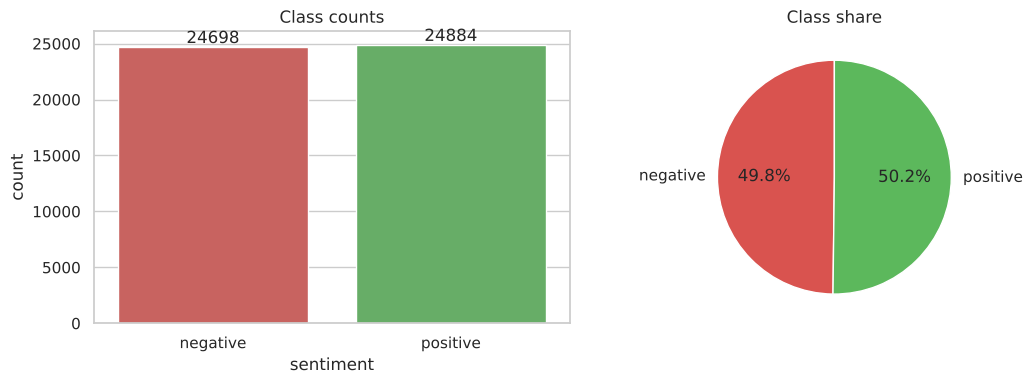

In [25]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
sns.countplot(data=df_clean, x='sentiment', palette=['#d9534f','#5cb85c'], order=['negative','positive'], ax=ax[0])
ax[0].set_title('Class counts')
for p in ax[0].patches: ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax[1].pie(counts[['negative','positive']], labels=['negative','positive'], autopct='%1.1f%%', colors=['#d9534f','#5cb85c'], startangle=90)
ax[1].set_title('Class share')
plt.tight_layout(); plt.show()

In [26]:
imbalance_ratio = counts.max()/counts.min()
print(f'Imbalance ratio: {imbalance_ratio:.3f}  (1.0 = perfectly balanced)')

Imbalance ratio: 1.008  (1.0 = perfectly balanced)


The data is (almost) perfectly balanced, so **accuracy is a fair metric** and we don't need resampling or class weights.

## 5. Reading raw reviews

In [27]:
for i in range(3):
    print('POSITIVE #',i,'\n', df_clean[df_clean.sentiment=='positive']['review'].iloc[i][:600], '\n', '-'*80)

POSITIVE # 0 
 One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly o 
 --------------------------------------------------------------------------------
POSITIVE # 1 
 A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got al

In [28]:
for i in range(3):
    print('NEGATIVE #',i,'\n', df_clean[df_clean.sentiment=='negative']['review'].iloc[i][:600], '\n', '-'*80)

NEGATIVE # 0 
 Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zombie.<br /><br />OK, first of all when you're going to make a film you must Decide if its a thriller or a drama! As a drama the movie is watchable. Parents are divorcing & arguing like in real life. And then we have Jake with his closet which totally ruins all the film! I expected to see a BOOGEYMAN similar movie, and instead i watched a drama with some m 
 --------------------------------------------------------------------------------
NEGATIVE # 1 
 This show was an amazing, fresh & innovative idea in the 70's when it first aired. The first 7 or 8 years were brilliant, but things dropped off after that. By 1990, the show was not really funny anymore, and it's continued its decline further to the complete waste of time it is today.

### 5.1 Noise we can already spot

Reviews are scraped web text, so expect HTML tags (`<br />`), URLs, digits, odd characters, emoticons, and shouting in CAPS. Let's measure each one.

In [29]:
checks = {
 'HTML tags':        df_clean['review'].str.contains(r'<[^>]+>', regex=True),
 'URLs':             df_clean['review'].str.contains(r'http\S+|www\.\S+', regex=True),
 'Digits':           df_clean['review'].str.contains(r'\d', regex=True),
 'Exclamation marks':df_clean['review'].str.contains('!', regex=False),
 'Question marks':   df_clean['review'].str.contains(r'\?', regex=True),
 'ALLCAPS word(3+)': df_clean['review'].str.contains(r'\b[A-Z]{3,}\b', regex=True),
 'Emoticons :) :(':  df_clean['review'].str.contains(r'[:;]-?[)(DP]', regex=True),
 'Non-ASCII chars':  df_clean['review'].apply(lambda s: not s.isascii()),
}
noise = pd.Series({k: v.mean()*100 for k,v in checks.items()}).sort_values(ascending=False)
noise.round(2).to_frame('% of reviews')

,% of reviews
HTML tags,58.42
Digits,56.04
ALLCAPS word(3+),38.24
Exclamation marks,34.69
Question marks,29.59
Non-ASCII chars,9.33
Emoticons :) :(,1.35
URLs,0.40


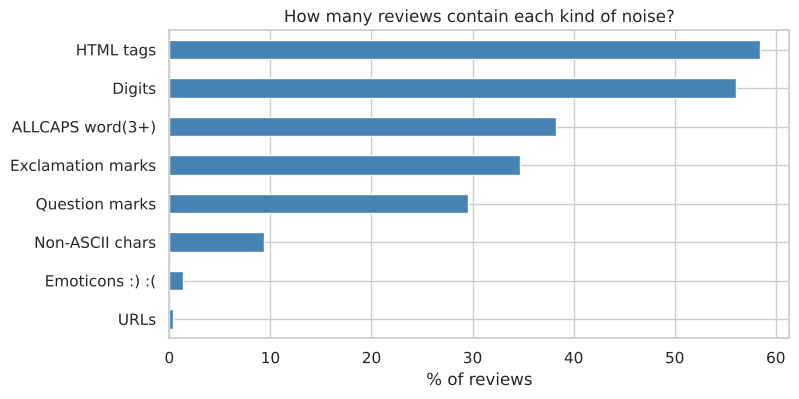

In [30]:
noise.plot(kind='barh', figsize=(8,4), color='steelblue'); plt.xlabel('% of reviews'); plt.title('How many reviews contain each kind of noise?'); plt.gca().invert_yaxis(); plt.show()

In [31]:
df_clean[checks['HTML tags']]['review'].str.findall(r'<[^>]+>').explode().value_counts().head(10)

review
<br />        200409
<i>                8
</i>               8
<grin>             2
<=8.<br />         2
< Cough >          2
<p>                1
< YES >            1
<3 <br />          1
<<<<<br />         1
Name: count, dtype: int64

In [32]:
df_clean[checks['Non-ASCII chars']]['review'].head(3).tolist()

['\'War movie\' is a Hollywood genre that has been done and redone so many times that clichéd dialogue, rehashed plot and over-the-top action sequences seem unavoidable for any conflict dealing with large-scale combat. Once in a while, however, a war movie comes along that goes against the grain and brings a truly original and compelling story to life on the silver screen. The Civil War-era "Cold Mountain," starring Jude Law, Nicole Kidman and Renée Zellweger is such a film.<br /><br />Then again, calling Cold Mountain" a war movie is not entirely accurate. True enough, the film opens with a (quite literally) quick-and-dirty battle sequence that puts "Glory" director Edward Zwick shame. However, "Cold Mountain" is not so much about the Civil War itself as it is about the period and the people of the times. The story centers around disgruntled Confederate soldier Inman, played by Jude Law, who becomes disgusted with the gruesome war and homesick for the beautiful hamlet of Cold Mountain

### 5.2 Noise vs. sentiment

In [33]:
rows=[]
for k,v in checks.items():
    rows.append({'noise':k, 'positive %': v[df_clean.sentiment=='positive'].mean()*100, 'negative %': v[df_clean.sentiment=='negative'].mean()*100})
nz = pd.DataFrame(rows).set_index('noise').round(2); nz

,positive %,negative %
noise,,
HTML tags,57.14,59.72
URLs,0.43,0.36
Digits,54.28,57.82
Exclamation marks,33.90,35.49
Question marks,21.50,37.73
ALLCAPS word(3+),35.65,40.85
Emoticons :) :(,1.65,1.04
Non-ASCII chars,8.52,10.14


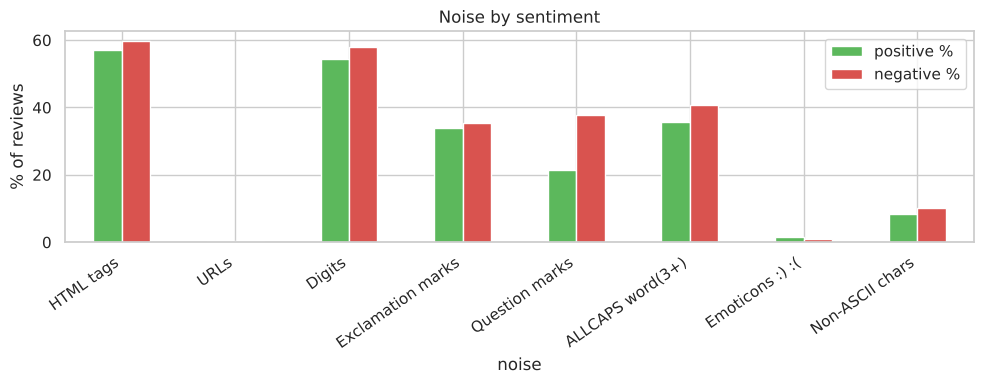

In [34]:
nz.plot(kind='bar', figsize=(10,4), color=['#5cb85c','#d9534f']); plt.ylabel('% of reviews'); plt.title('Noise by sentiment'); plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

## 6. Quick sanity checks on labels

In [35]:
pos_words = ['excellent','wonderful','masterpiece','brilliant','loved','perfect']
neg_words = ['awful','terrible','worst','boring','waste','horrible']
for w in pos_words+neg_words:
    has = df_clean['review'].str.lower().str.contains(r'\b'+w+r'\b', regex=True)
    print(f"{w:12s} → P(positive | contains word) = {df_clean.loc[has,'label'].mean():.3f}   (n={has.sum()})")

excellent    → P(positive | contains word) = 0.808   (n=3532)


wonderful    → P(positive | contains word) = 0.814   (n=2764)


masterpiece  → P(positive | contains word) = 0.729   (n=1201)


brilliant    → P(positive | contains word) = 0.762   (n=2070)


loved        → P(positive | contains word) = 0.757   (n=2514)


...

terrible     → P(positive | contains word) = 0.143   (n=2672)


worst        → P(positive | contains word) = 0.093   (n=4387)


boring       → P(positive | contains word) = 0.194   (n=3032)


waste        → P(positive | contains word) = 0.070   (n=2502)


horrible     → P(positive | contains word) = 0.155   (n=2082)


Words like *masterpiece* skew strongly positive, *worst/waste/awful* strongly negative — the labels look sensible and the task is learnable from words alone.

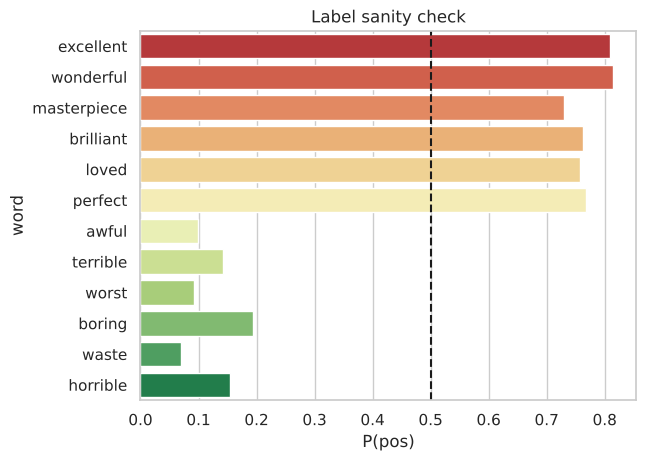

In [36]:
lex = pd.DataFrame({'word': pos_words+neg_words, 'P(pos)': [df_clean.loc[df_clean['review'].str.lower().str.contains(r'\b'+w+r'\b', regex=True),'label'].mean() for w in pos_words+neg_words]})
sns.barplot(data=lex, y='word', x='P(pos)', palette='RdYlGn'); plt.axvline(0.5, color='k', ls='--'); plt.title('Label sanity check'); plt.show()

## 7. Train / test hygiene decision

In [37]:
from sklearn.model_selection import train_test_split
train, test = train_test_split(df_clean, test_size=0.2, stratify=df_clean['label'], random_state=42)
print(train.shape, test.shape)
print(train['label'].mean().round(4), test['label'].mean().round(4))

(39665, 3) (9917, 3)
0.5019 0.5019


In [38]:
print('Reviews shared between train and test:', len(set(train['review']) & set(test['review'])))

Reviews shared between train and test: 0


We split with **stratification** (same class ratio in both) and confirmed no leakage. We will reuse `random_state=42` everywhere so all notebooks use the same split.

In [39]:
import os
os.makedirs('data', exist_ok=True)
df_clean.to_csv('data/imdb_dedup.csv', index=False)
print('saved data/imdb_dedup.csv', df_clean.shape)

saved data/imdb_dedup.csv (49582, 3)


## 8. Summary of findings
| Finding | Value |
|---|---|
| Rows (raw → de-duplicated) | 50,000 → see output above |
| Missing values | none |
| Class balance | ≈ 50 / 50 |
| Main noise | `<br />` HTML tags, digits, punctuation, some CAPS |
| Leakage risk | duplicates removed; stratified split verified |

**Next:** [02 – Text statistics](02_eda_text_statistics.ipynb)